# 01 - Data Exploration

The target `Price` is measured in **Lakhs of Sri Lankan Rupees**: 1 Lakh = LKR 100,000.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
data_path = Path('../data/processed/cleaned_vehicle_data.csv')
df = pd.read_csv(data_path)
df['Date'] = pd.to_datetime(df['Date'])
print(df.shape)
df.head()

(9536, 17)


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price,Vehicle Age
0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0,9
1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0,8
2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5,7
3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0,7
4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5,7


In [2]:
display(df.info())
display(df.describe(include='all').T)
print('Missing values:', int(df.isna().sum().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 9536 entries, 0 to 9535
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Brand           9536 non-null   str           
 1   Model           9536 non-null   str           
 2   YOM             9536 non-null   int64         
 3   Engine (cc)     9536 non-null   float64       
 4   Gear            9536 non-null   str           
 5   Fuel Type       9536 non-null   str           
 6   Millage(KM)     9536 non-null   float64       
 7   Town            9536 non-null   str           
 8   Date            9536 non-null   datetime64[us]
 9   Leasing         9536 non-null   str           
 10  Condition       9536 non-null   str           
 11  AIR CONDITION   9536 non-null   str           
 12  POWER STEERING  9536 non-null   str           
 13  POWER MIRROR    9536 non-null   str           
 14  POWER WINDOW    9536 non-null   str           
 15  Price          

None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Brand,9536,50,TOYOTA,3021,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,9536,1555,ALTO,360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YOM,9536.0,NaN,NaN,NaN,2006.681208,1956.0,2001.0,2009.0,2015.0,2024.0,9.865689
Engine (cc),9536.0,NaN,NaN,NaN,1265.25323,573.0,1000.0,1300.0,1500.0,4800.0,403.610849
Gear,9536,2,Automatic,6162,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fuel Type,9536,4,Petrol,7650,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Millage(KM),9536.0,NaN,NaN,NaN,201506.711409,11000.0,110000.0,176000.0,264000.0,759000.0,108522.577484
Town,9536,107,Colombo,1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,9536,NaN,NaN,NaN,2025-01-13 05:41:16.510067,2024-12-03 00:00:00,2024-12-28 00:00:00,2025-01-18 00:00:00,2025-02-01 00:00:00,2025-02-05 00:00:00,NaN
Leasing,9536,2,No Leasing,9134,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values: 0


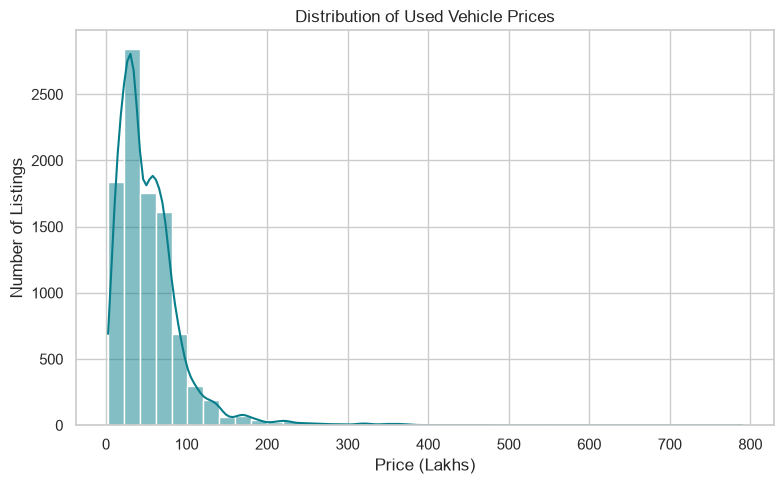

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df['Price'], bins=40, kde=True, ax=ax, color='#087E8B')
ax.set(title='Distribution of Used Vehicle Prices', xlabel='Price (Lakhs)', ylabel='Number of Listings')
plt.tight_layout()
plt.show()

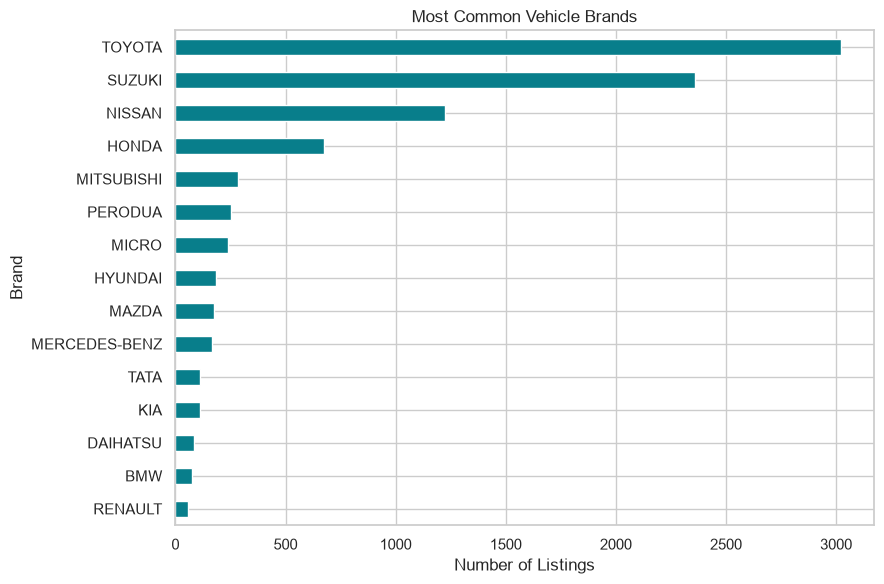

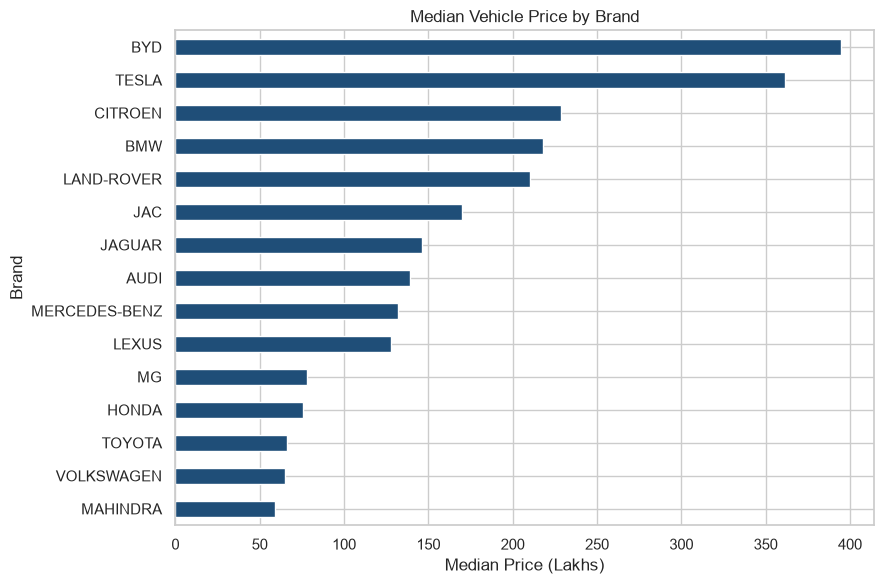

In [4]:
top_brands = df['Brand'].value_counts().head(15)
fig, ax = plt.subplots(figsize=(9, 6))
top_brands.sort_values().plot(kind='barh', ax=ax, color='#087E8B')
ax.set(title='Most Common Vehicle Brands', xlabel='Number of Listings', ylabel='Brand')
plt.tight_layout()
plt.show()

brand_median = df.groupby('Brand')['Price'].median().sort_values().tail(15)
fig, ax = plt.subplots(figsize=(9, 6))
brand_median.plot(kind='barh', ax=ax, color='#1F4E78')
ax.set(title='Median Vehicle Price by Brand', xlabel='Median Price (Lakhs)', ylabel='Brand')
plt.tight_layout()
plt.show()

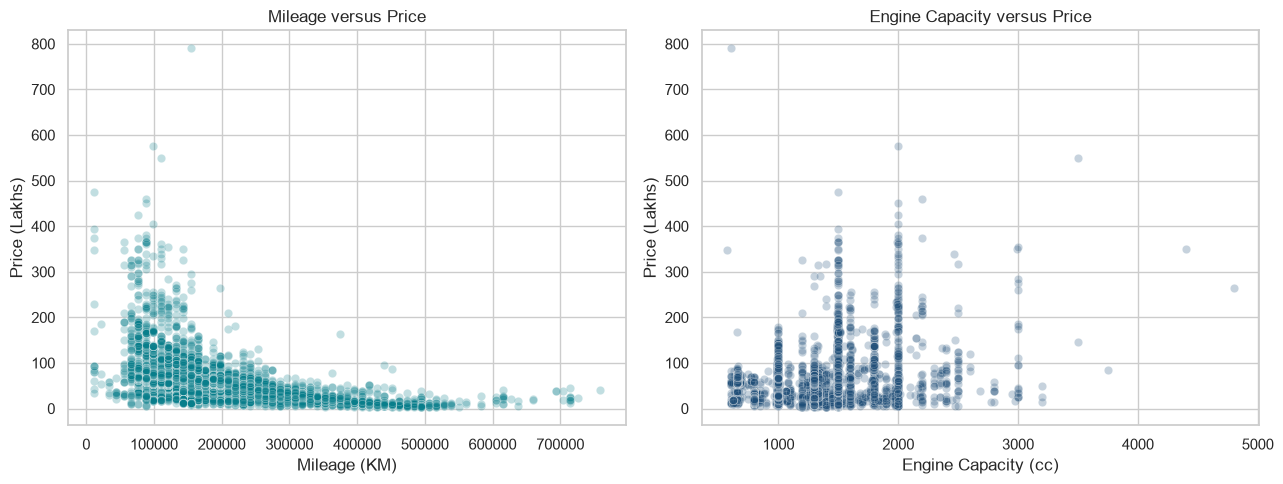

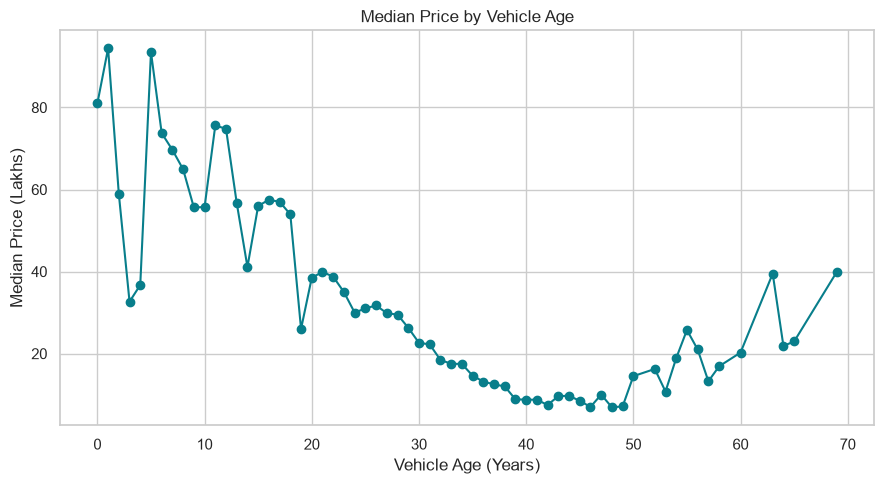

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x='Millage(KM)', y='Price', alpha=.25, ax=ax[0], color='#087E8B')
ax[0].set(title='Mileage versus Price', xlabel='Mileage (KM)', ylabel='Price (Lakhs)')
sns.scatterplot(data=df, x='Engine (cc)', y='Price', alpha=.25, ax=ax[1], color='#1F4E78')
ax[1].set(title='Engine Capacity versus Price', xlabel='Engine Capacity (cc)', ylabel='Price (Lakhs)')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
age_price = df.groupby('Vehicle Age')['Price'].median()
age_price.plot(ax=ax, marker='o', color='#087E8B')
ax.set(title='Median Price by Vehicle Age', xlabel='Vehicle Age (Years)', ylabel='Median Price (Lakhs)')
plt.tight_layout()
plt.show()

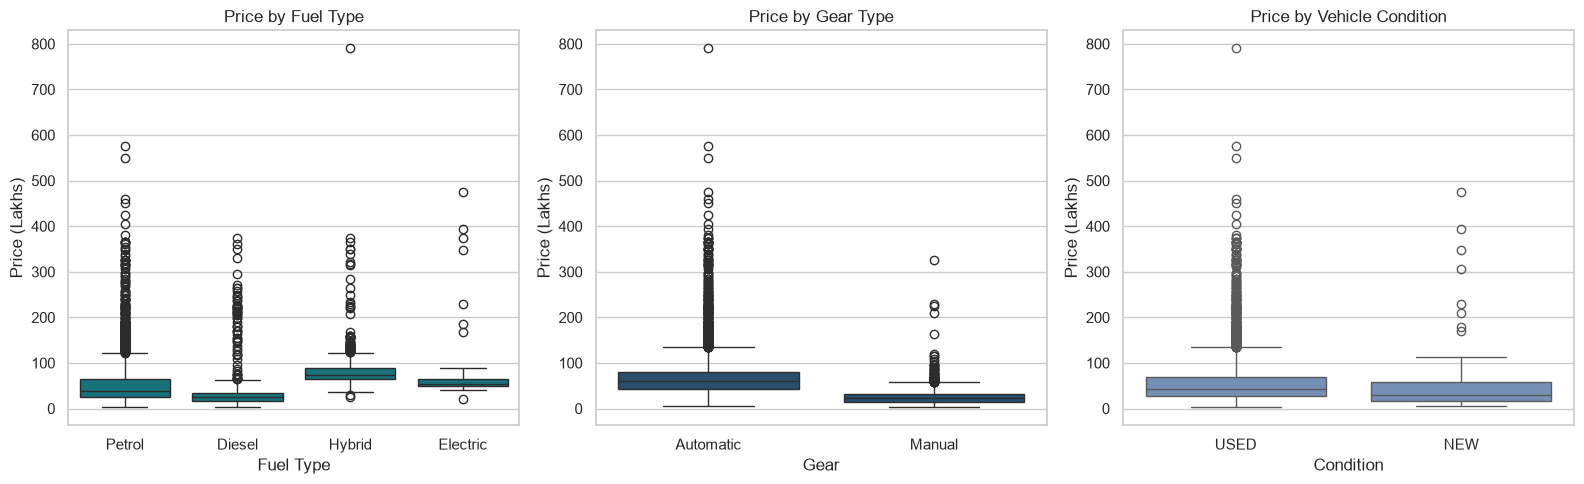

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
sns.boxplot(data=df, x='Fuel Type', y='Price', ax=ax[0], color='#087E8B')
ax[0].set(title='Price by Fuel Type', xlabel='Fuel Type', ylabel='Price (Lakhs)')
sns.boxplot(data=df, x='Gear', y='Price', ax=ax[1], color='#1F4E78')
ax[1].set(title='Price by Gear Type', xlabel='Gear', ylabel='Price (Lakhs)')
sns.boxplot(data=df, x='Condition', y='Price', ax=ax[2], color='#6C8EBF')
ax[2].set(title='Price by Vehicle Condition', xlabel='Condition', ylabel='Price (Lakhs)')
plt.tight_layout()
plt.show()

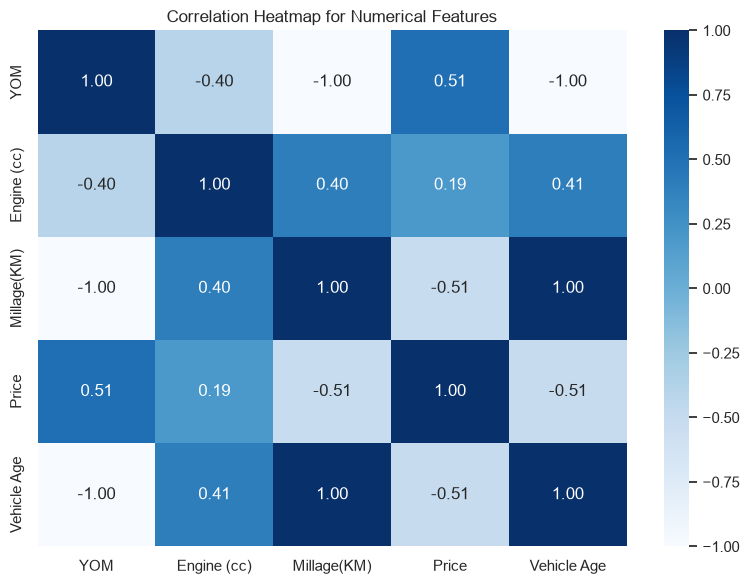

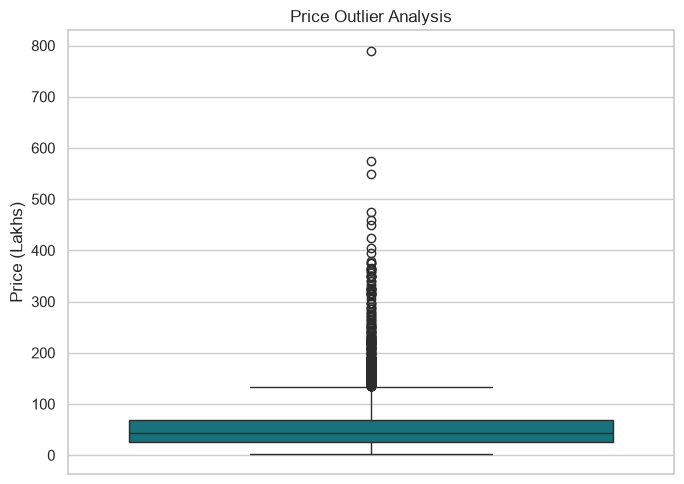

In [7]:
numeric = df[['YOM','Engine (cc)','Millage(KM)','Price','Vehicle Age']].copy()
corr = numeric.corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', ax=ax)
ax.set(title='Correlation Heatmap for Numerical Features')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, y='Price', ax=ax, color='#087E8B')
ax.set(title='Price Outlier Analysis', ylabel='Price (Lakhs)')
plt.tight_layout()
plt.show()

## Interpretation

Record observations about distributions, relationships, and outliers after running the notebook. Do not claim model performance here.